# Visualize Box Diffusion Results

Load a trained `BoxSetDiffusionDecoder` checkpoint and visualize predicted bounding boxes
alongside ground-truth annotations on CrowdPose images.

In [15]:
%matplotlib inline

In [25]:
from pathlib import Path

# ── Paths ─────────────────────────────────────────────────────────────────────
RUN_DIR = Path("results/box_diffusion_benchmark/box_diffusion_benchmark/20260526_235638")
CKPT_PATH = RUN_DIR / "checkpoints/epoch089-val_bbox_AP.ckpt"
HYDRA_CFG = RUN_DIR / ".hydra/config.yaml"

ANN_DIR  = Path("data/crowdpose/annotations")
IMG_ROOT = Path("data/crowdpose/images")
SPLIT    = "val"  # val | test

# ── Inference settings ────────────────────────────────────────────────────────
MAX_SIZE     = 128   # resize longest side to this before backbone
SCORE_THRESH = 0.5   # objectness threshold for predicted boxes
TOP_K        = 20    # max predicted boxes shown per image

# ── Visualisation ─────────────────────────────────────────────────────────────
N_IMAGES = 3   # images shown per variant (1-step and 5-step)
SEED     = 0

DEVICE = "cuda"  # cpu | cuda


## 0. Training metrics

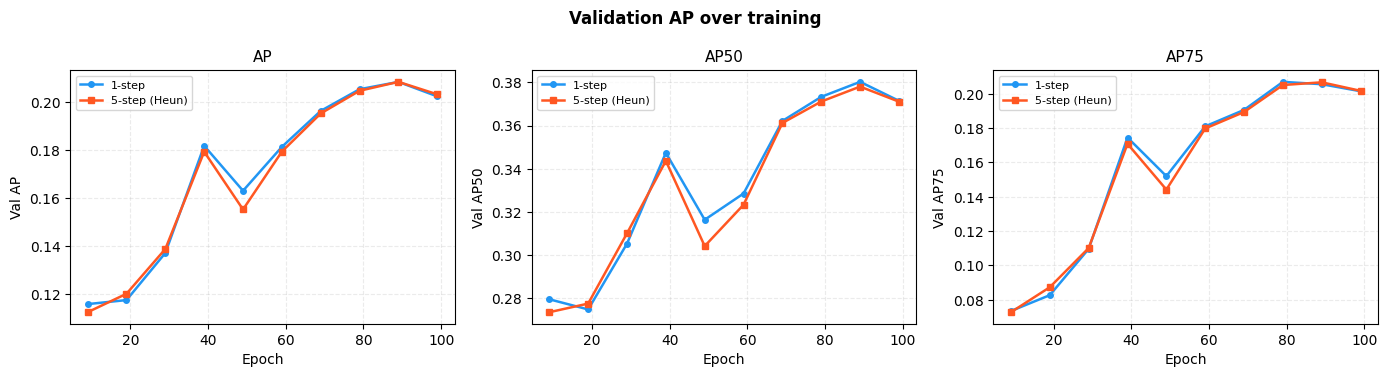

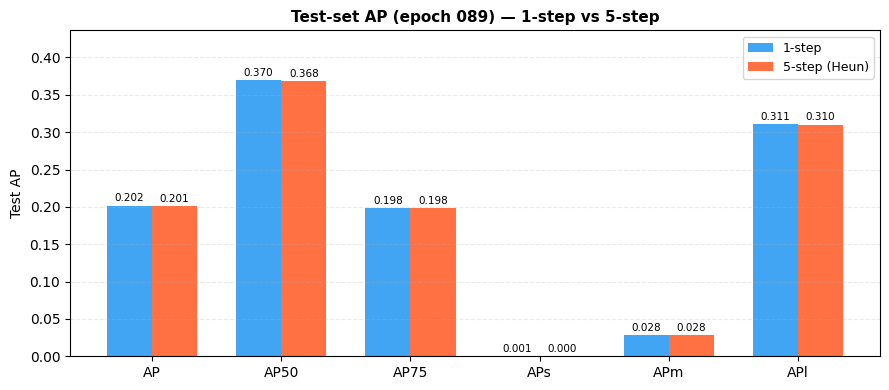


Metric      1-step    5-step         Δ
------------------------------------
AP          0.2016    0.2015  -0.0001
AP50        0.3698    0.3680  -0.0018
AP75        0.1984    0.1982  -0.0002
APs         0.0005    0.0004  -0.0001
APm         0.0283    0.0283  + 0.0000
APl         0.3112    0.3102  -0.0011


In [30]:
import json

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

metrics_csv       = RUN_DIR / "csv_logs/metrics.csv"
test_results_path = RUN_DIR / "test_results.json"

df = pd.read_csv(metrics_csv)

# ── Val curves (logged every ~10 epochs) ─────────────────────────────────────
VAL_METRICS = {
    "AP":  ("ap-val/1-step/bbox/AP",   "ap-val/5-step/bbox/AP"),
    "AP50":("ap-val/1-step/bbox/AP50", "ap-val/5-step/bbox/AP50"),
    "AP75":("ap-val/1-step/bbox/AP75", "ap-val/5-step/bbox/AP75"),
}

COLORS   = {"1-step": "#2196F3", "5-step (Heun)": "#FF5722"}
MARKERS  = {"1-step": "o",       "5-step (Heun)": "s"}

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=False)
fig.suptitle("Validation AP over training", fontsize=12, fontweight="bold")

for ax, (metric_name, (col1, col5)) in zip(axes, VAL_METRICS.items()):
    sub = df[["epoch", col1, col5]].dropna()
    ax.plot(sub["epoch"], sub[col1], color=COLORS["1-step"],       marker=MARKERS["1-step"],
            markersize=4, linewidth=1.8, label="1-step")
    ax.plot(sub["epoch"], sub[col5], color=COLORS["5-step (Heun)"],marker=MARKERS["5-step (Heun)"],
            markersize=4, linewidth=1.8, label="5-step (Heun)")
    ax.set_title(metric_name, fontsize=11)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Val " + metric_name)
    ax.grid(True, alpha=0.25, linestyle="--")
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.2f"))
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# ── Test-set bar chart ────────────────────────────────────────────────────────
if test_results_path.exists():
    with open(test_results_path) as fh:
        test_data = json.load(fh)
    m = test_data.get("metrics", {})

    bar_metrics = ["AP", "AP50", "AP75", "APs", "APm", "APl"]
    vals_1step  = [m.get(f"ap-test/1-step/bbox/{k}", float("nan")) for k in bar_metrics]
    vals_5step  = [m.get(f"ap-test/5-step/bbox/{k}", float("nan")) for k in bar_metrics]

    x      = np.arange(len(bar_metrics))
    width  = 0.35

    fig2, ax2 = plt.subplots(figsize=(9, 4))
    bars1 = ax2.bar(x - width / 2, vals_1step, width, label="1-step",       color=COLORS["1-step"],       alpha=0.85)
    bars2 = ax2.bar(x + width / 2, vals_5step, width, label="5-step (Heun)",color=COLORS["5-step (Heun)"],alpha=0.85)

    for bar in list(bars1) + list(bars2):
        h = bar.get_height()
        if not np.isnan(h):
            ax2.text(bar.get_x() + bar.get_width() / 2, h + 0.003,
                     f"{h:.3f}", ha="center", va="bottom", fontsize=7.5)

    ax2.set_xticks(x)
    ax2.set_xticklabels(bar_metrics, fontsize=10)
    ax2.set_ylabel("Test AP")
    ax2.set_title("Test-set AP (epoch 089) — 1-step vs 5-step", fontsize=11, fontweight="bold")
    ax2.legend(fontsize=9)
    ax2.grid(axis="y", alpha=0.25, linestyle="--")
    ax2.set_ylim(0, max(max(vals_1step), max(vals_5step)) * 1.18)
    plt.tight_layout()
    plt.show()

    # Print table
    print(f"\n{'Metric':<8}  {'1-step':>8}  {'5-step':>8}  {'Δ':>8}")
    print("-" * 36)
    for name, v1, v5 in zip(bar_metrics, vals_1step, vals_5step):
        delta = v5 - v1
        sign  = "+" if delta >= 0 else ""
        print(f"{name:<8}  {v1:>8.4f}  {v5:>8.4f}  {sign}{delta:>7.4f}")


In [18]:
import random
import sys
from pathlib import Path

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision.io as tvio
import torchvision.transforms.functional as TF
from omegaconf import OmegaConf
from torchvision.transforms import InterpolationMode

# Ensure the workspace root is on the path
ROOT = Path(".").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.data_module import resize_and_pad_to_square
from src.data.datasets import PoseDataset
from src.data.transforms import boxes_padded_canonical_to_pixel_xywh
from src.decoders.diffusion.box_set import BoxSetDiffusionDecoderConfig
from src.features import BaseFeatureExtractorConfig
from src.training.box_diffusion_module import _image_tokens_and_centers

## 1. Build backbone + decoder and load checkpoint

In [19]:
raw_cfg = OmegaConf.load(HYDRA_CFG)

backbone_cfg = BaseFeatureExtractorConfig.from_hydra_config(raw_cfg.backbone)
decoder_cfg  = BoxSetDiffusionDecoderConfig.from_hydra_config(raw_cfg.decoder)

backbone = backbone_cfg.build()
decoder_cfg.image_token_dim = backbone.out_channels
decoder = decoder_cfg.build()

ckpt = torch.load(CKPT_PATH, map_location="cpu", weights_only=False)
sd = ckpt["state_dict"]

# Backbone is frozen: checkpoint only stores buffers, not pretrained weights.
backbone.load_state_dict(
    {k[len("backbone."):]: v for k, v in sd.items() if k.startswith("backbone.")},
    strict=False,
)
decoder.load_state_dict({k[len("decoder."):]: v for k, v in sd.items() if k.startswith("decoder.")})

backbone.eval().to(DEVICE)
decoder.eval().to(DEVICE)

test_ap = None
if test_results_path.exists():
    test_ap = test_data.get("metrics", {}).get("ap-test/5-step/bbox/AP")

print(f"Backbone : {type(backbone).__name__}  out_channels={backbone.out_channels}")
print(f"Decoder  : {type(decoder).__name__}  num_slots={decoder.num_slots}")
print(f"Test AP (5-step) : {test_ap:.4f}" if test_ap is not None else "Test AP  : N/A")
print("Checkpoint loaded.")


Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

Backbone : RadioFeatureExtractor  out_channels=1280
Decoder  : BoxSetDiffusionDecoder  num_slots=20
Test AP (5-step) : 0.2015
Checkpoint loaded.


## 2. Sample images from the dataset

In [20]:
ann_path = ANN_DIR / f"crowdpose_{SPLIT}.json"
ds = PoseDataset.from_path(ann_path, img_root=IMG_ROOT)

random.seed(SEED)
indices = random.sample(range(len(ds)), min(N_IMAGES, len(ds)))
samples = [ds.samples[i] for i in indices]

print(f"Dataset: {len(ds)} images  |  showing {len(samples)}")

Dataset: 2000 images  |  showing 3


## 3. Run inference

In [27]:
def _run_inference(samples, num_steps):
    out_list = []
    with torch.no_grad():
        for sample in samples:
            img_uint8 = tvio.read_image(sample["img_path"])
            if img_uint8.shape[0] == 1:
                img_uint8 = img_uint8.expand(3, -1, -1)
            _, orig_h, orig_w = img_uint8.shape
            img_float = img_uint8.float().div_(255.0)

            img_sq, _ = resize_and_pad_to_square(img_float, MAX_SIZE)
            img_batch = img_sq.unsqueeze(0).to(DEVICE)

            features = backbone(image=img_batch)
            tokens, centers = _image_tokens_and_centers(features, feature_key="spatial")

            out = decoder.sample(
                image_tokens=tokens,
                patch_centers=centers,
                num_inference_steps=num_steps,
                sigma_min=raw_cfg.training_module.sigma_min,
                sigma_max=raw_cfg.training_module.sigma_max,
                rho=raw_cfg.training_module.rho,
            )

            pred_boxes_canon = out["pred_boxes"].cpu()
            obj_scores = out["obj_logits"].sigmoid().cpu().squeeze(0)

            img_hw = torch.tensor([[orig_h, orig_w]], dtype=torch.float32)
            pred_boxes_xywh = boxes_padded_canonical_to_pixel_xywh(pred_boxes_canon, img_hw).squeeze(0)
            x, y, w, h = pred_boxes_xywh.unbind(-1)
            pred_boxes_xyxy = torch.stack([x, y, x + w, y + h], dim=-1)

            out_list.append({
                "img_uint8":       img_uint8,
                "pred_boxes_xyxy": pred_boxes_xyxy,
                "obj_scores":      obj_scores,
                "gt_boxes_xywh":   sample.get("gt_boxes_pixel", torch.zeros(0, 4)),
            })
    return out_list


results_1step = _run_inference(samples, num_steps=1)
results_5step = _run_inference(samples, num_steps=5)
print(f"Inference done: {len(samples)} images × 2 variants (1-step, 5-step)")


Inference done: 3 images × 2 variants (1-step, 5-step)


## 4. Visualise predictions vs GT

In [22]:
%matplotlib inline

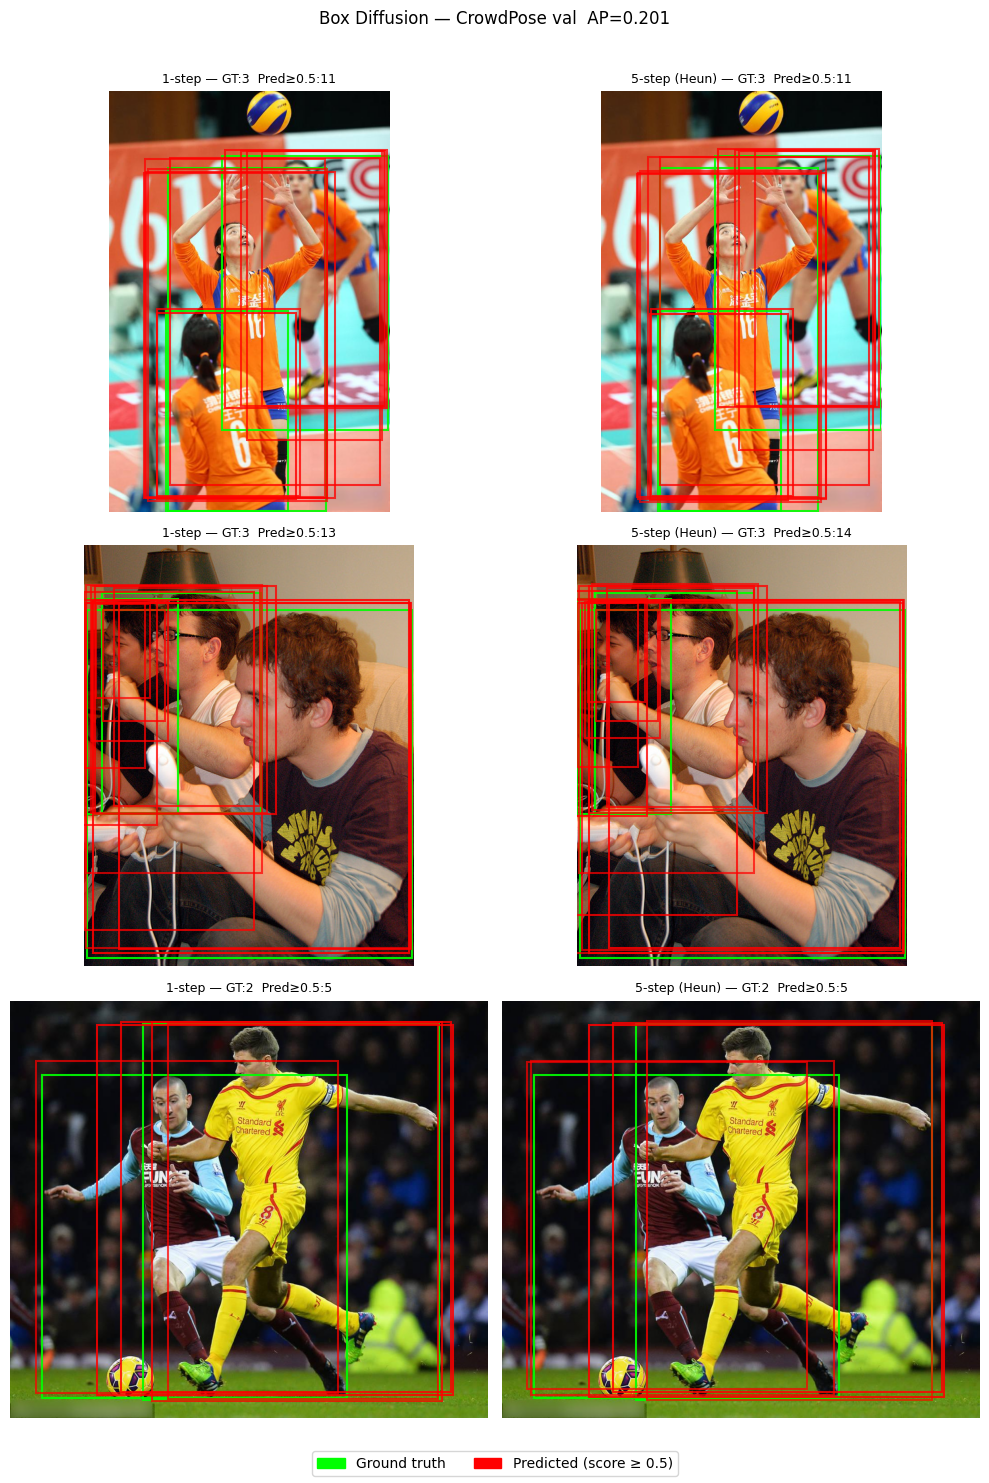

In [28]:
def _draw_boxes(ax, boxes_xyxy, color, alpha=0.9, linewidth=1.5):
    for box in boxes_xyxy:
        x1, y1, x2, y2 = box
        rect = plt.Rectangle(
            (float(x1), float(y1)), float(x2 - x1), float(y2 - y1),
            edgecolor=color, facecolor="none", linewidth=linewidth, alpha=alpha,
        )
        ax.add_patch(rect)


fig, axes = plt.subplots(N_IMAGES, 2, figsize=(10, 5 * N_IMAGES))
axes = np.array(axes).reshape(N_IMAGES, 2)

for col, (col_results, col_title) in enumerate(
    zip([results_1step, results_5step], ["1-step", "5-step (Heun)"])
):
    for row, res in enumerate(col_results):
        ax = axes[row, col]
        ax.imshow(res["img_uint8"].permute(1, 2, 0).numpy())

        # GT boxes (green)
        gt = res["gt_boxes_xywh"]
        if gt is not None and len(gt) > 0:
            gt_np = gt.numpy()
            gx, gy, gw, gh = gt_np[:, 0], gt_np[:, 1], gt_np[:, 2], gt_np[:, 3]
            _draw_boxes(ax, np.stack([gx, gy, gx + gw, gy + gh], axis=-1), color="lime")

        # Predicted boxes (red, filtered by score)
        scores = res["obj_scores"].numpy()
        pred   = res["pred_boxes_xyxy"].numpy()
        keep   = np.where(scores >= SCORE_THRESH)[0]
        keep   = keep[np.argsort(-scores[keep])][:TOP_K]
        for idx in keep:
            s = float(scores[idx])
            rect = plt.Rectangle(
                (float(pred[idx, 0]), float(pred[idx, 1])),
                float(pred[idx, 2] - pred[idx, 0]), float(pred[idx, 3] - pred[idx, 1]),
                edgecolor="red", facecolor="none", linewidth=1.5, alpha=float(0.4 + 0.6 * s),
            )
            ax.add_patch(rect)

        n_gt = len(gt) if gt is not None else 0
        ax.set_title(f"{col_title} — GT:{n_gt}  Pred≥{SCORE_THRESH:.1f}:{len(keep)}", fontsize=9)
        ax.axis("off")

gt_patch   = mpatches.Patch(color="lime", label="Ground truth")
pred_patch = mpatches.Patch(color="red",  label=f"Predicted (score ≥ {SCORE_THRESH})")
fig.legend(handles=[gt_patch, pred_patch], loc="lower center", ncol=2, fontsize=10)

ap_str = f"  AP={test_ap:.3f}" if test_ap is not None else ""
fig.suptitle(f"Box Diffusion — CrowdPose {SPLIT}{ap_str}", fontsize=12)
plt.tight_layout(rect=[0, 0.03, 1, 0.97])
plt.show()


## 5. Score distribution

1-step: 29/60 slots above threshold (48.3%)
5-step (Heun): 30/60 slots above threshold (50.0%)


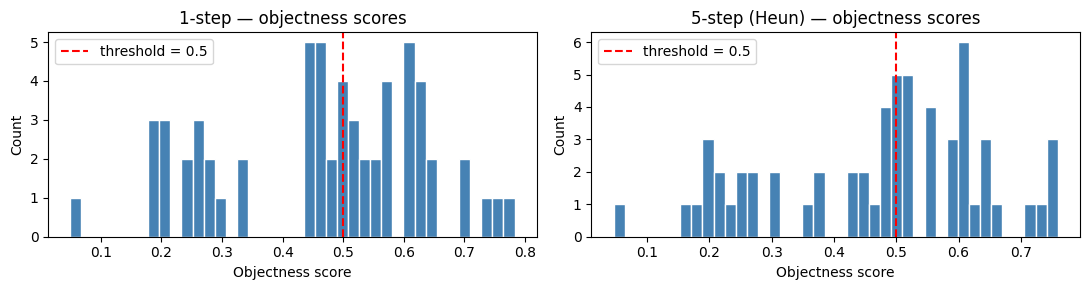

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))

for ax, results, label in zip(axes, [results_1step, results_5step], ["1-step", "5-step (Heun)"]):
    all_scores = torch.cat([r["obj_scores"] for r in results]).numpy()
    ax.hist(all_scores, bins=40, color="steelblue", edgecolor="white")
    ax.axvline(SCORE_THRESH, color="red", linestyle="--", label=f"threshold = {SCORE_THRESH}")
    ax.set_xlabel("Objectness score")
    ax.set_ylabel("Count")
    ax.set_title(f"{label} — objectness scores")
    ax.legend()
    n_above = (all_scores >= SCORE_THRESH).sum()
    print(f"{label}: {n_above}/{len(all_scores)} slots above threshold "
          f"({100 * n_above / len(all_scores):.1f}%)")

plt.tight_layout()
plt.show()
